# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'jhaff2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

N = 250 | min eigenvalue of C: 9.23515833450677e-05
pass 0: N used = 250, new cuts: [('2002bf', 6.7), ('2008hj', 6.1)]
pass 1: N used = 248, new cuts: []
removed: ['2002bf', '2008hj'] | N kept = 248
median x1_err = 0.17463499999999998 | std of x1 = 1.0557898645744144
median c_err  = 0.0338595 | std of c  = 0.0918177037185688
cofactor check (want True True): True True


C:\Users\jkhaf\AppData\Local\miniforge3\envs\astr457\lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


ms per gradient: 0.052552223205566406 (want ~1 ms or less)


C:\Users\jkhaf\AppData\Local\miniforge3\envs\astr457\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [mu_x1, sigma_x1_pop, mu_c, sigma_c_pop, x1_true, c_true, alpha, beta, gamma, M, sigma_int]
C:\Users\jkhaf\AppData\Local\miniforge3\envs\astr457\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random cra

Output()

Sampling 1 chain for 200 tune and 100 draw iterations (200 + 100 draws total) took 6 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


trial divergences: 0
trial step size  : 0.41277919903475
min sigma_c_pop  : 0.07234653492218532


C:\Users\jkhaf\AppData\Local\miniforge3\envs\astr457\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_x1, sigma_x1_pop, mu_c, sigma_c_pop, x1_true, c_true, alpha, beta, gamma, M, sigma_int]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 34 seconds.


Largest Rhat      = 1.006
Smallest bulk ESS = 4008
Divergences       = 0
alpha      = 0.1493 [0.1399, 0.1586]
beta       = 3.0250 [2.9007, 3.1521]
gamma      = -0.0475 [-0.0662, -0.0279]
sigma_int  = 0.1140 [0.1053, 0.1224]
ML latent: alpha=0.1493 beta=3.0270 gamma=-0.0472 sigma_int=0.1120
a_mid: mean = 0.133 +/- 0.001
b_mid: mean = 2.693 +/- 0.013
a_lat: mean = 0.140 +/- 0.002
b_lat: mean = 2.894 +/- 0.016
true alpha = 0.14  true beta = 2.9
x1: error variance / total variance = 0.060, reliability = 0.940
c: error variance / total variance = 0.165, reliability = 0.835


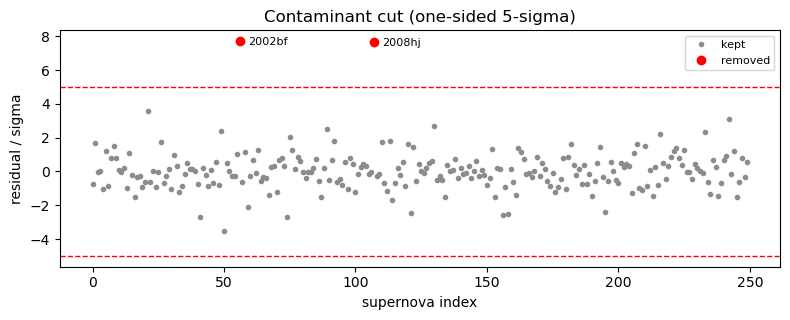

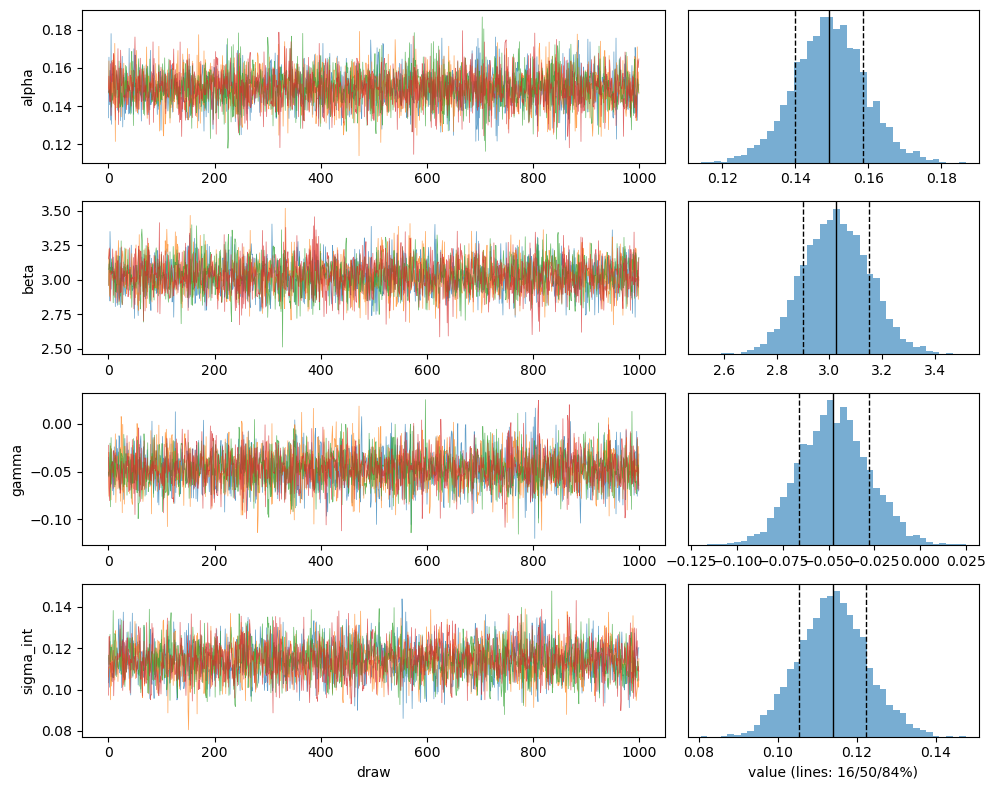

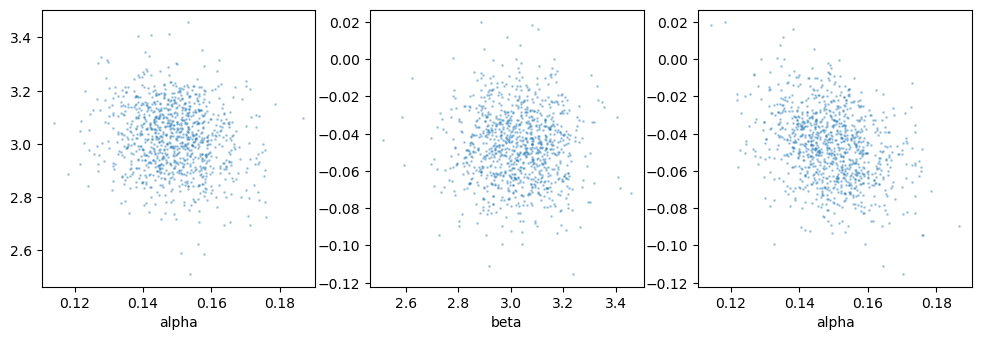

In [2]:
import time, os
import numpy as np, pandas as pd
import pymc as pm, pytensor.tensor as pt, arviz as az
from scipy.optimize import minimize
from astropy.cosmology import FlatLambdaCDM

# ============================================================
# Rebuild every input from the catalog (no dependence on earlier cells)
# ============================================================
sn    = pd.read_csv(MIDTERM + "p2_pantheon_sne.csv")
N_all = len(sn)
z     = sn["z"].to_numpy(float)
d     = sn[["mB", "x1", "c"]].to_numpy(float)
step  = (sn["host_logmass"].to_numpy(float) > 10).astype(float)

C = np.zeros((N_all, 3, 3))
C[:,0,0], C[:,1,1], C[:,2,2] = sn["mB_err"]**2, sn["x1_err"]**2, sn["c_err"]**2
C[:,0,1] = C[:,1,0] = sn["cov_mB_x1"]
C[:,0,2] = C[:,2,0] = sn["cov_mB_c"]
C[:,1,2] = C[:,2,1] = sn["cov_x1_c"]

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu_z  = cosmo.distmod(z).value
spec2 = (5/np.log(10) * 250.0 / (299792.458 * z))**2        # 250 km/s, as on the midterm
full  = dict(d=d, C=C, mu_z=mu_z, spec2=spec2, step=step)
sub   = lambda D, sel: {k: v[sel] for k, v in D.items()}
print("N =", N_all, "| min eigenvalue of C:", np.linalg.eigvalsh(C).min())

# ============================================================
# Midterm model (2b likelihood): measured x1, c as regressors
# ============================================================
def mid_resid(th, D):
    M, a, b, g, ls = th
    return D['d'][:,0] - (M + D['mu_z'] - a*D['d'][:,1] + b*D['d'][:,2] + g*D['step'])

def mid_var(th, D):
    M, a, b, g, ls = th
    C_ = D['C']
    vCv = (C_[:,0,0] + a**2*C_[:,1,1] + b**2*C_[:,2,2]
           + 2*a*C_[:,0,1] - 2*b*C_[:,0,2] - 2*a*b*C_[:,1,2])
    return vCv + D['spec2'] + np.exp(2*ls)

def mid_nll(th, D):
    v, r = mid_var(th, D), mid_resid(th, D)
    return 0.5*np.sum(r**2/v + np.log(v) + np.log(2*np.pi))

def fit_mid(D):
    return minimize(mid_nll, [-19.3, 0.14, 2.9, -0.04, np.log(0.11)], args=(D,),
                    method='Nelder-Mead',
                    options=dict(maxiter=40000, xatol=1e-9, fatol=1e-9))

# ============================================================
# Contaminants: midterm method (iterated one-sided 5-sigma cut)
# ============================================================
cut = np.zeros(N_all, bool)
for it in range(5):
    th  = fit_mid(sub(full, ~cut)).x
    s   = mid_resid(th, full) / np.sqrt(mid_var(th, full))
    new = (s > 5) & ~cut                                    # fainter than the relation only
    print(f"pass {it}: N used = {(~cut).sum()}, new cuts: "
          f"{[(sn['name'].iloc[i], round(float(s[i]), 1)) for i in np.where(new)[0]]}")
    if not new.any():
        break
    cut |= new
keep = ~cut
print("removed:", list(sn['name'][cut]), "| N kept =", int(keep.sum()))

d_k, C_k, mu_z_k, spec2_k, step_k = (np.ascontiguousarray(full[k][keep], dtype=float)
                                     for k in ['d', 'C', 'mu_z', 'spec2', 'step'])
N_k = int(keep.sum())

# ============================================================
# Day 19 rule
# ============================================================
print("median x1_err =", np.median(np.sqrt(C_k[:,1,1])), "| std of x1 =", d_k[:,1].std())
print("median c_err  =", np.median(np.sqrt(C_k[:,2,2])), "| std of c  =", d_k[:,2].std())
NONCENTERED = False      # errors << widths -> centered; flip only if the trial run shows funnel trouble

# ============================================================
# Latent-variable model (explicit 3x3 cofactor form of the MvNormal density)
# ============================================================
with pm.Model() as latent_tripp_model:
    mu_x1        = pm.Normal("mu_x1", 0.0, 5.0)
    sigma_x1_pop = pm.HalfNormal("sigma_x1_pop", 2.0)
    mu_c         = pm.Normal("mu_c", 0.0, 0.5)
    sigma_c_pop  = pm.HalfNormal("sigma_c_pop", 0.3)

    if NONCENTERED:
        x1_raw  = pm.Normal("x1_raw", 0.0, 1.0, shape=N_k)
        c_raw   = pm.Normal("c_raw",  0.0, 1.0, shape=N_k)
        x1_true = pm.Deterministic("x1_true", mu_x1 + sigma_x1_pop*x1_raw)
        c_true  = pm.Deterministic("c_true",  mu_c  + sigma_c_pop*c_raw)
        init = {"x1_raw": np.zeros(N_k), "c_raw": np.zeros(N_k)}
    else:
        x1_true = pm.Normal("x1_true", mu_x1, sigma_x1_pop, shape=N_k)
        c_true  = pm.Normal("c_true",  mu_c,  sigma_c_pop,  shape=N_k)
        init = {"x1_true": d_k[:,1].copy(), "c_true": d_k[:,2].copy()}

    alpha     = pm.Normal("alpha", 0.14, 0.5)
    beta      = pm.Normal("beta",  3.0, 2.0)
    gamma     = pm.Normal("gamma", 0.0, 0.3)
    M         = pm.Normal("M", -19.3, 1.0)
    sigma_int = pm.HalfNormal("sigma_int", 0.2)

    mB_true = M + mu_z_k - alpha*x1_true + beta*c_true + gamma*step_k

    # only S00 depends on parameters (sigma_int^2 + pec variance go on mB only)
    T = pt.as_tensor_variable
    S00 = T(C_k[:,0,0] + spec2_k) + sigma_int**2
    S01, S02 = T(C_k[:,0,1]), T(C_k[:,0,2])
    S11, S12, S22 = T(C_k[:,1,1]), T(C_k[:,1,2]), T(C_k[:,2,2])

    cof00 = S11*S22 - S12**2
    cof01 = -(S01*S22 - S12*S02)
    cof02 = S01*S12 - S11*S02
    cof11 = S00*S22 - S02**2
    cof12 = -(S00*S12 - S01*S02)
    cof22 = S00*S11 - S01**2
    det   = S00*cof00 + S01*cof01 + S02*cof02

    r0 = T(d_k[:,0]) - mB_true
    r1 = T(d_k[:,1]) - x1_true
    r2 = T(d_k[:,2]) - c_true
    maha = (r0**2*cof00 + r1**2*cof11 + r2**2*cof22
            + 2*r0*r1*cof01 + 2*r0*r2*cof02 + 2*r1*r2*cof12) / det

    pm.Potential("obs", -0.5*pt.sum(maha + pt.log(det) + 3*np.log(2*np.pi)))

# ---- cofactor algebra check against numpy ----
i0 = 0
S_np = C_k[i0].copy(); S_np[0,0] += spec2_k[i0] + 0.1**2
r_np = np.array([0.3, -0.2, 0.05])
a00, a01, a02, a11, a12, a22 = S_np[0,0], S_np[0,1], S_np[0,2], S_np[1,1], S_np[1,2], S_np[2,2]
k00 = a11*a22 - a12**2; k01 = -(a01*a22 - a12*a02); k02 = a01*a12 - a11*a02
k11 = a00*a22 - a02**2; k12 = -(a00*a12 - a01*a02); k22 = a00*a11 - a01**2
det_ = a00*k00 + a01*k01 + a02*k02
m_cof = (r_np[0]**2*k00 + r_np[1]**2*k11 + r_np[2]**2*k22
         + 2*r_np[0]*r_np[1]*k01 + 2*r_np[0]*r_np[2]*k02 + 2*r_np[1]*r_np[2]*k12)/det_
print("cofactor check (want True True):",
      np.isclose(m_cof, r_np @ np.linalg.solve(S_np, r_np)), np.isclose(det_, np.linalg.det(S_np)))

# ---- timing ----
f  = latent_tripp_model.compile_dlogp()
p0 = latent_tripp_model.initial_point()
f(p0)
t0 = time.time()
for _ in range(50): f(p0)
print("ms per gradient:", 1000*(time.time() - t0)/50, "(want ~1 ms or less)")

CORES = min(4, os.cpu_count() or 1)      # if you get a multiprocessing error, set CORES = 1

# ---- short trial run ----
RUN_TRIAL = True
if RUN_TRIAL:
    with latent_tripp_model:
        trial = pm.sample(draws=100, tune=200, chains=1, cores=1, init="adapt_diag",
                          initvals=init, random_seed=1, progressbar=True)
    print("trial divergences:", int(trial.sample_stats["diverging"].values.sum()))
    print("trial step size  :", float(trial.sample_stats["step_size"].values.mean()))
    print("min sigma_c_pop  :", float(trial.posterior["sigma_c_pop"].min()))

# ---- full run (set RUN_TRIAL = False once the trial looks healthy) ----
with latent_tripp_model:
    trace = pm.sample(draws=1000, tune=1000, chains=4, cores=CORES,
                      target_accept=0.95, random_seed=42,
                      init="adapt_diag", initvals=init)

rhat, ess = az.rhat(trace), az.ess(trace, method="bulk")
print("Largest Rhat      =", round(max(float(np.nanmax(rhat[v].values)) for v in rhat.data_vars), 3))
print("Smallest bulk ESS =", round(min(float(np.nanmin(ess[v].values))  for v in ess.data_vars)))
print("Divergences       =", int(trace.sample_stats["diverging"].values.sum()))
for par in ["alpha", "beta", "gamma", "sigma_int"]:
    q16, q50, q84 = np.percentile(trace.posterior[par].values.ravel(), [16, 50, 84])
    print(f"{par:10s} = {q50:.4f} [{q16:.4f}, {q84:.4f}]")

# ============================================================
# Latent model, marginal likelihood (true x1, c integrated out)
# ============================================================
def lat_nll(th, D):
    M, a, b, g, lsi, mx, lsx, mc, lsc = th
    sint, sx, sc = np.exp(lsi), np.exp(lsx), np.exp(lsc)
    n = len(D['d'])
    m = np.column_stack([M + D['mu_z'] + g*D['step'] - a*mx + b*mc,
                         np.full(n, mx), np.full(n, mc)])
    A = np.array([[-a, b], [1.0, 0.0], [0.0, 1.0]])
    S = D['C'] + (A @ np.diag([sx**2, sc**2]) @ A.T)[None]
    S[:,0,0] += D['spec2'] + sint**2
    r = D['d'] - m
    maha = np.einsum('ni,ni->n', r, np.linalg.solve(S, r[:,:,None])[:,:,0])
    return 0.5*np.sum(maha + np.linalg.slogdet(S)[1] + 3*np.log(2*np.pi))

def fit_lat(D):
    x0 = [-19.3, 0.14, 2.9, -0.05, np.log(0.11),
          D['d'][:,1].mean(), np.log(D['d'][:,1].std()),
          D['d'][:,2].mean(), np.log(D['d'][:,2].std())]
    return minimize(lat_nll, x0, args=(D,), method='L-BFGS-B')

r = fit_lat(sub(full, keep)).x
print(f"ML latent: alpha={r[1]:.4f} beta={r[2]:.4f} gamma={r[3]:.4f} sigma_int={np.exp(r[4]):.4f}")

# ============================================================
# 1.3 simulation (recipe of the solution's 2e)
# ============================================================
truth = dict(M=-19.30, alpha=0.14, beta=2.9, gamma=-0.06, sint=0.11)
NSIM  = 40
rng   = np.random.default_rng(2026)
Lc    = np.linalg.cholesky(C)
x1t, ct = d[:,1], d[:,2]

res = {k: [] for k in ["a_mid", "b_mid", "a_lat", "b_lat"]}
for i in range(NSIM):
    e  = np.einsum('nij,nj->ni', Lc, rng.standard_normal((N_all, 3)))
    mB = (truth['M'] + mu_z - truth['alpha']*x1t + truth['beta']*ct + truth['gamma']*step
          + e[:,0] + truth['sint']*rng.standard_normal(N_all)
          + np.sqrt(spec2)*rng.standard_normal(N_all))
    Ds = dict(full, d=np.column_stack([mB, x1t + e[:,1], ct + e[:,2]]))
    rm, rl = fit_mid(Ds).x, fit_lat(Ds).x
    res["a_mid"].append(rm[1]); res["b_mid"].append(rm[2])
    res["a_lat"].append(rl[1]); res["b_lat"].append(rl[2])

for k, v in res.items():
    v = np.array(v)
    print(f"{k}: mean = {v.mean():.3f} +/- {v.std(ddof=1)/np.sqrt(NSIM):.3f}")
print("true alpha =", truth['alpha'], " true beta =", truth['beta'])

for name, j in [("x1", 1), ("c", 2)]:
    noise = np.mean(C[:, j, j]) / np.var(d[:, j])
    print(f"{name}: error variance / total variance = {noise:.3f}, reliability = {1-noise:.3f}")
# ============================================================
# Extra graphs (run after everything above)
# ============================================================
import matplotlib.pyplot as plt
post = trace.posterior
pars = ["alpha", "beta", "gamma", "sigma_int"]
draws = {p: post[p].values.reshape(post[p].shape[0], -1) for p in pars}   # (chain, draw)

# (a) contaminant cut: standardized midterm residuals, cut points in red
fig, ax = plt.subplots(figsize=(8, 3.3))
idx = np.arange(N_all)
ax.plot(idx[keep], s[keep], '.', color='0.55', label='kept')
ax.plot(idx[cut], s[cut], 'ro', label='removed')
ax.axhline(5, color='r', ls='--', lw=1); ax.axhline(-5, color='r', ls='--', lw=1)
for i in np.where(cut)[0]:
    ax.annotate(sn['name'].iloc[i], (i, s[i]), textcoords='offset points', xytext=(6, -3), fontsize=8)
ax.set_xlabel('supernova index'); ax.set_ylabel('residual / sigma')
ax.set_title('Contaminant cut (one-sided 5-sigma)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# (b) chains and posteriors for the four parameters
fig, ax = plt.subplots(4, 2, figsize=(10, 8), gridspec_kw=dict(width_ratios=[2, 1]))
for row, p in enumerate(pars):
    for ch in draws[p]:
        ax[row, 0].plot(ch, lw=0.5, alpha=0.7)
    flat = draws[p].ravel()
    q16, q50, q84 = np.percentile(flat, [16, 50, 84])
    ax[row, 1].hist(flat, bins=40, color='C0', alpha=0.6)
    for q, ls in [(q16, '--'), (q50, '-'), (q84, '--')]:
        ax[row, 1].axvline(q, color='k', ls=ls, lw=1)
    ax[row, 0].set_ylabel(p); ax[row, 1].set_yticks([])
ax[-1, 0].set_xlabel('draw'); ax[-1, 1].set_xlabel('value (lines: 16/50/84%)')
plt.tight_layout(); plt.show()

# (c) pairwise posteriors
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a_, (px, py) in zip(ax, [("alpha", "beta"), ("beta", "gamma"), ("alpha", "gamma")]):
    a_.plot(draws[px].ravel()[::4], draws[py].ravel()[::4], '.', ms=2, alpha=0.3)
    a_.set_xlabel(px);

In [3]:
for name, j, coef in [("x1", 1, -0.14), ("c", 2, 2.9)]:
    print(name, "error-covariance term =", np.mean(C[:, 0, j]) / (coef * np.var(d[:, j])))

x1 error-covariance term = -0.012622948275953538
c error-covariance term = 0.06821850311515126


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

1. The few that should be white is c and x1, since they are noisey messurements of the true value but are assumed correct in the midterm. The midterm also lacks population circles and errors from true to measured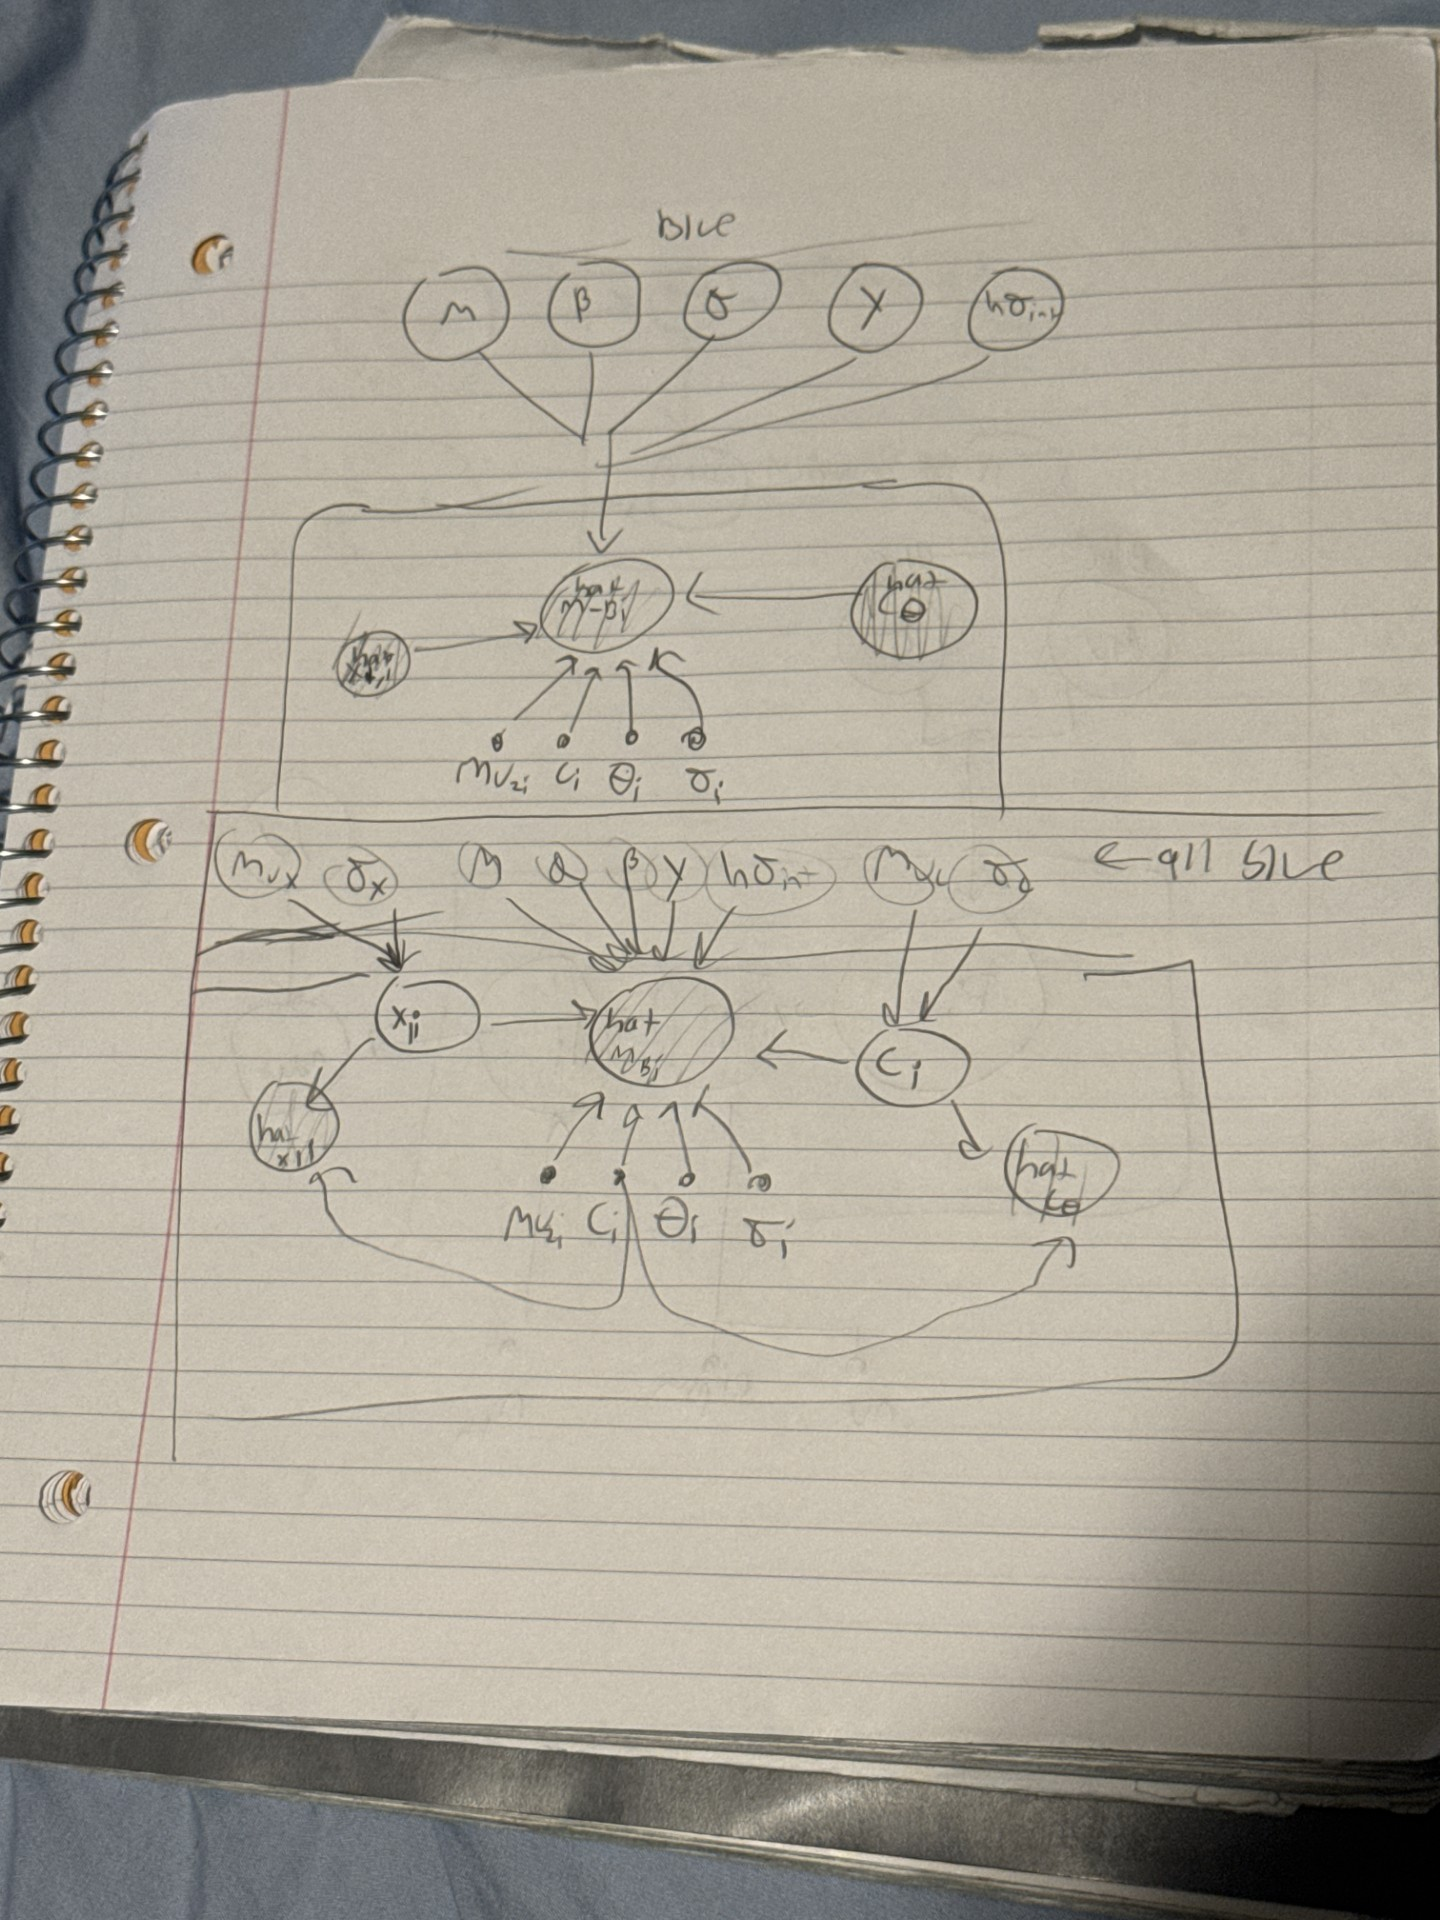

2. all supernovae were first used, than the ones outside of 5 sigma were cut until nothing new got cut (it was repeated). this removed 2 (2002bf at +6.7 sigma and 2008hj at +6.1 sigma, both fainter than the relation, so N = 248 kept). It doesnt bais sigma as 5 sigma is far from sigma int. It should be centered: the median measurement errors are well below the population widths (x1: 0.17 vs a std of 1.06; c: 0.034 vs a std of 0.092), so each supernova's data pin down its own latent values and there is no funnel; the trial run (0 divergences, step size 0.41) agreed. the R is 1.006, and smallest bulk ESS is 4008, while 0 divergences.

| parameter | latent model (PyMC, median, 68%) | midterm value |
|---|---|---|
| alpha | 0.149 +0.009/-0.009 | 0.146 +/- 0.011 |
| beta | 3.03 +0.13/-0.12 | 2.75 +0.13/-0.13 |
| gamma [mag] | -0.048 +0.020/-0.019 | -0.052 +/- 0.024 |
| sigma_int [mag] | 0.114 +0.008/-0.009 | 0.152 +0.010/-0.009 |
   Compared with the midterm, beta moves up from 2.75 to 3.03 (a shift of +0.28, about two midterm error bars), the direction and size the 1.3 simulation predicts for removing the attenuation (midterm model low by about 0.2). alpha barely changes (0.146 to 0.149), as expected since x1 is measured much more precisely relative to its spread, and gamma is unchanged within its error bar. sigma_int drops from 0.152 to 0.114 mag, so the latent model needs less intrinsic scatter once the errors in the regressors are treated properly.



3. Simulation (40 fake datasets, true beta = 2.9, true alpha = 0.14): midterm model mean beta-hat = 2.693 +/- 0.013 (alpha-hat = 0.133 +/- 0.001); latent model mean beta-hat = 2.894 +/- 0.016 (alpha-hat = 0.140 +/- 0.002). So the midterm model is low by about 0.21 (roughly 16 standard errors) while the latent model recovers the truth.

The latent model gets closer than the midterm model when simulated, the midterm biases B low as the messured C includes scatter added to the true C, there ends up being a weaker link betweeen c and m_b, pushing B down. Latent modle does account for noise. B is biased more than a as c has a higher varience, while x1 islower, which corresponds to a higher B miss and lower a miss respectivily. mB and c error are positivly correlated,at 6%, which is thenpushing B back up. X1 covararience is small so it doesn't change much.

Numbers behind this: the measurement-error variance is 16.5% of the total variance in c (reliability 0.835) but only 6.0% in x1 (reliability 0.940). Regressing on the noisy value shrinks the slope by roughly the reliability, so beta should drop to about 0.835 x 2.9 = 2.4, and alpha to about 0.94 x 0.14 = 0.13. The m_B-c error covariance term (+0.068, relative to beta) moves beta back up to roughly 0.90 x 2.9 = 2.6, close to the simulated 2.69, while the x1 term is only -0.013, so alpha ends near 0.13, matching the simulated 0.133.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

file: ../../labs/08/data/jhaff2.csv
rows: 1500 | non-finite: 0 | non-integer: 0
min n = 33 | max n = 1300 | rows with n <= 32: 0 | rows equal to the max: 58
10 smallest: [33. 33. 33. 33. 33. 33. 33. 33. 33. 33.]
10 largest : [1300. 1300. 1300. 1300. 1300. 1300. 1300. 1300. 1300. 1300.]
fix chosen: ['censor_top']
sources used: 1500 of 1500 | effective threshold: n > 32 | censoring cap: 1300.0
F= 0.03  gammainc: 0.000156   poisson.sf: 0.000156
F= 0.08  gammainc: 0.167885   poisson.sf: 0.167885
F= 0.10  gammainc: 0.453171   poisson.sf: 0.453171
F= 0.12  gammainc: 0.742372   poisson.sf: 0.742372
F= 0.20  gammainc: 0.999350   poisson.sf: 0.999350
F= 1.00  gammainc: 1.000000   poisson.sf: 1.000000
p_det = 0.5 at F = 0.1029 F0 (ln F = -2.274); mean counts there = 32.7


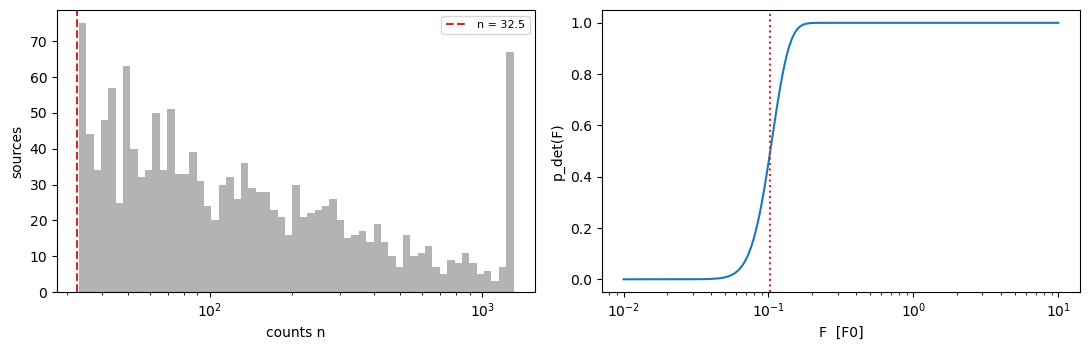

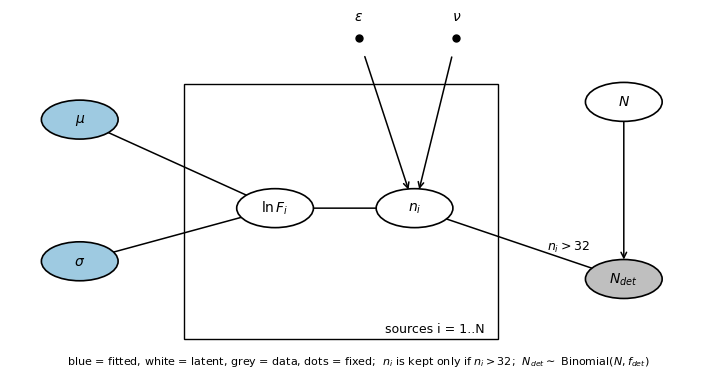


uncertainties = curvature (Hessian) of the log-likelihood at the maximum
data    model                      mu              sigma
raw     naive        -0.6978 +/- 0.0289    1.1124 +/- 0.0206
raw     corrected    -1.6040 +/- 0.1276    1.6320 +/- 0.0677
fixed   naive        -0.6823 +/- 0.0300    1.1533 +/- 0.0220
fixed   corrected    -1.9594 +/- 0.1968    1.8639 +/- 0.0952

f_det = 0.5697 | N_det = 1500 | N_total = 2633 +/- 205 | missed = 1133 +/- 205   (error from the (mu, sigma) covariance only)
grid/2 check (naive): d_mu = +0.0e+00, d_sigma = +0.0e+00
grid/2 check (corrected): d_mu = -1.5e-07, d_sigma = +1.9e-07

simulated survey keeps 1466 of 2633 (data: 1500) | KS test data vs simulation: p = 0.812


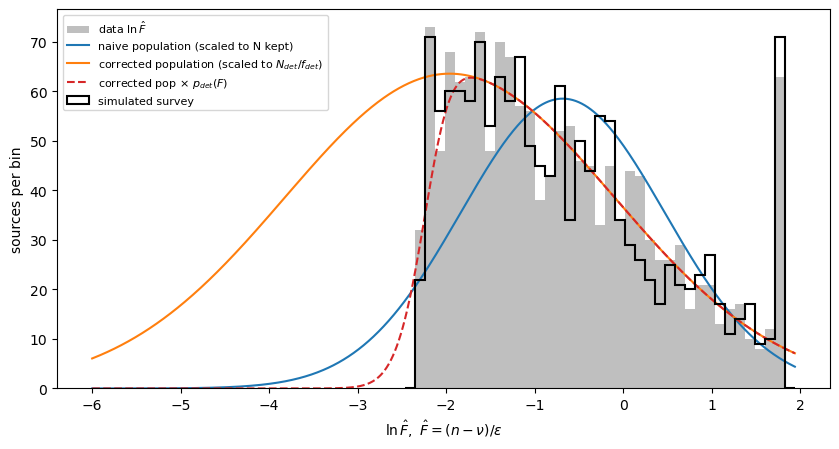

ignoring the detector shifts mu by +1.277 and sigma by -0.711 (naive minus corrected, in ln F)


In [4]:
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammainc, gammaln
from scipy.optimize import minimize, brentq
from matplotlib.patches import Circle, Rectangle

EPS, NU, THR0 = 226.27, 9.373, 32
lam  = lambda F: EPS*np.asarray(F, float) + NU
pdet = lambda F, thr=THR0: gammainc(thr + 1, lam(F))     # P(n > thr) = P(n >= thr+1)

# ============================================================
# 2.1  Load, diagnose, choose a fix
# ============================================================
path = os.path.join(LAB, f"{NETID}.csv")
if not os.path.exists(path):
    hits = glob.glob(f"../../**/{NETID}.csv", recursive=True)
    if not hits: raise FileNotFoundError(f"cannot find {NETID}.csv under {LAB}")
    path = hits[0]
df  = pd.read_csv(path)
col = 'n_counts' if 'n_counts' in df.columns else df.columns[0]
raw = pd.to_numeric(df[col], errors='coerce').to_numpy(float)
finite = np.isfinite(raw)
n_all = raw[finite]
nmin, nmax = n_all.min(), n_all.max()
n_below   = int((n_all <= THR0).sum())
n_at_max  = int((n_all == nmax).sum())
print(f"file: {path}\nrows: {len(raw)} | non-finite: {(~finite).sum()} | non-integer: {(n_all != np.round(n_all)).sum()}")
print(f"min n = {nmin:.0f} | max n = {nmax:.0f} | rows with n <= 32: {n_below} | rows equal to the max: {n_at_max}")
print("10 smallest:", np.sort(n_all)[:10]); print("10 largest :", np.sort(n_all)[-10:])

# ---- choose the fix: 'auto', or a list from {'drop_low', 'raise_thr', 'censor_top'}, or [] for none ----
FIX = 'auto'
if FIX == 'auto':
    FIX = []
    if n_below > 0:            FIX.append('drop_low')      # rows below the stated threshold
    if n_at_max >= 5:          FIX.append('censor_top')    # pile-up at the top value (saturation)
    if nmin >= 38 and n_below == 0: FIX.append('raise_thr')  # nothing between 33 and nmin: real cut is higher
print("fix chosen:", FIX if FIX else "none")

n_use, thr_eff, cap = n_all.copy(), THR0, None
if 'drop_low' in FIX:   n_use = n_use[n_use > THR0]
if 'raise_thr' in FIX:  thr_eff = int(nmin) - 1; n_use = n_use[n_use > thr_eff]
if 'censor_top' in FIX: cap = float(nmax)
print(f"sources used: {len(n_use)} of {len(raw)} | effective threshold: n > {thr_eff} | censoring cap: {cap}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(n_all, bins=np.logspace(np.log10(max(nmin, 1)), np.log10(nmax), 60), color='0.7')
ax[0].set_xscale('log'); ax[0].axvline(THR0 + .5, color='C3', ls='--', label='n = 32.5')
if thr_eff != THR0: ax[0].axvline(thr_eff + .5, color='C2', ls='--', label=f'n = {thr_eff}.5')
ax[0].set_xlabel('counts n'); ax[0].set_ylabel('sources'); ax[0].legend(fontsize=8)

# ============================================================
# 2.2  p_det(F): closed form, check, half-detection flux
# ============================================================
for F in [0.03, 0.08, 0.1, 0.12, 0.2, 1.0]:
    print(f"F={F:5.2f}  gammainc: {pdet(F):.6f}   poisson.sf: {stats.poisson.sf(THR0, lam(F)):.6f}")
F50 = brentq(lambda F: pdet(F) - 0.5, 1e-3, 10)
print(f"p_det = 0.5 at F = {F50:.4f} F0 (ln F = {np.log(F50):.3f}); mean counts there = {lam(F50):.1f}")
Fp = np.logspace(-2, 1, 400)
ax[1].semilogx(Fp, pdet(Fp)); ax[1].axvline(F50, color='C3', ls=':')
ax[1].set_xlabel('F  [F0]'); ax[1].set_ylabel('p_det(F)'); plt.tight_layout(); plt.show()

# ============================================================
# 2.3  The selection graph
# ============================================================
def node(a, xy, label, kind):
    if kind == 'fixed':
        a.plot(*xy, 'ko', ms=5); a.text(xy[0], xy[1] + 0.05, label, ha='center', fontsize=10)
    else:
        fc = {'param': '#9ecae1', 'latent': 'white', 'data': '0.75'}[kind]
        a.add_patch(Circle(xy, 0.055, fc=fc, ec='k', lw=1.2, zorder=3))
        a.text(*xy, label, ha='center', va='center', fontsize=10, zorder=4)
def arrow(a, p, q):
    a.annotate('', xy=q, xytext=p, zorder=2, arrowprops=dict(arrowstyle='->', lw=1.1, shrinkA=14, shrinkB=14))

fg, axg = plt.subplots(figsize=(9, 4.6)); axg.set_xlim(0, 1); axg.set_ylim(0, 1); axg.axis('off')
axg.add_patch(Rectangle((0.25, 0.08), 0.45, 0.72, fill=False, ec='k'))
axg.text(0.68, 0.10, 'sources i = 1..N', ha='right', fontsize=9)
P = dict(mu=(0.10, 0.70), sig=(0.10, 0.30), lnF=(0.38, 0.45), n=(0.58, 0.45),
         eps=(0.50, 0.93), nu=(0.64, 0.93), N=(0.88, 0.75), Ndet=(0.88, 0.25))
node(axg, P['mu'], r'$\mu$', 'param');       node(axg, P['sig'], r'$\sigma$', 'param')
node(axg, P['lnF'], r'$\ln F_i$', 'latent'); node(axg, P['n'], r'$n_i$', 'latent')
node(axg, P['eps'], r'$\epsilon$', 'fixed'); node(axg, P['nu'], r'$\nu$', 'fixed')
node(axg, P['N'], r'$N$', 'latent');         node(axg, P['Ndet'], r'$N_{det}$', 'data')
for p, q in [('mu','lnF'), ('sig','lnF'), ('lnF','n'), ('eps','n'), ('nu','n'), ('n','Ndet'), ('N','Ndet')]:
    arrow(axg, P[p], P[q])
axg.text(0.77, 0.33, r'$n_i>32$', fontsize=9)
axg.text(0.5, 0.01, r'blue = fitted, white = latent, grey = data, dots = fixed;  $n_i$ is kept only if $n_i>32$;  '
         r'$N_{det}\sim$ Binomial$(N, f_{det})$', ha='center', fontsize=8)
plt.show()

# ============================================================
# 2.4  Grid likelihood: naive and detector-corrected
# ============================================================
def make_model(n_arr, thr, cap=None, dl=0.005, correct=True):
    lnF = np.arange(-14, 8 + dl/2, dl); F = np.exp(lnF); l = lam(F)
    cens  = np.zeros(len(n_arr), bool) if cap is None else (n_arr >= cap)
    n_cens = int(cens.sum())
    un, cnt = np.unique(n_arr[~cens], return_counts=True)
    pmf = np.exp(un[:, None]*np.log(l)[None, :] - l[None, :] - gammaln(un + 1)[:, None])
    sfc = gammainc(cap, l) if n_cens else None            # P(n >= cap), for censored rows
    pd_ = pdet(F, thr); Ndet = len(n_arr)
    def parts(mu, sig):
        w = np.exp(-0.5*((lnF - mu)/sig)**2)/(sig*np.sqrt(2*np.pi))*dl
        return pmf @ w, (np.sum(sfc*w) if n_cens else 1.0), np.sum(pd_*w)
    def nll(p):
        mu, sig = p
        if sig <= 0.02: return 1e12
        Li, Lc, fdet = parts(mu, sig)
        ll = np.sum(cnt*np.log(np.maximum(Li, 1e-300)))
        if n_cens: ll += n_cens*np.log(max(Lc, 1e-300))
        if correct: ll -= Ndet*np.log(max(fdet, 1e-300))   # subtract N_det ln f_det
        return -ll
    return nll, parts, Ndet

def num_hess(f, p, h=5e-3):
    p = np.asarray(p, float); H = np.zeros((2, 2))
    for i in range(2):
        for j in range(2):
            ei, ej = np.eye(2)[i]*h, np.eye(2)[j]*h
            H[i, j] = (f(p+ei+ej) - f(p+ei-ej) - f(p-ei+ej) + f(p-ei-ej))/(4*h*h)
    return H

def fit(n_arr, thr, cap, correct, dl=0.005):
    nll, parts, Ndet = make_model(n_arr, thr, cap, dl, correct)
    lf = np.log(np.maximum((n_arr - NU)/EPS, 1e-3))
    r  = minimize(nll, (lf.mean(), max(lf.std(), 0.3)), method='Nelder-Mead',
                  options=dict(xatol=1e-6, fatol=1e-8, maxiter=4000))
    cov = np.linalg.pinv(num_hess(nll, r.x))
    return r.x, np.sqrt(np.abs(np.diag(cov))), cov, parts, Ndet

print("\nuncertainties = curvature (Hessian) of the log-likelihood at the maximum")
print(f"{'data':7s} {'model':10s} {'mu':>18s} {'sigma':>18s}")
out = {}
for lab, arr, thr, cp in [('raw', n_all, THR0, None), ('fixed', n_use, thr_eff, cap)]:
    for correct in (False, True):
        p, e, cov, parts, Nd = fit(arr, thr, cp, correct)
        out[(lab, correct)] = (p, e, cov, parts, Nd)
        print(f"{lab:7s} {'corrected' if correct else 'naive':10s} {p[0]:9.4f} +/- {e[0]:.4f} {p[1]:9.4f} +/- {e[1]:.4f}")

p_nv, e_nv, _, _, _          = out[('fixed', False)]
p_c,  e_c,  cov_c, parts_c, Nd = out[('fixed', True)]
fdet = parts_c(*p_c)[2]; Ntot = Nd/fdet
Nfun = lambda p: Nd/parts_c(*p)[2]
g = np.array([(Nfun(p_c + 1e-3*np.eye(2)[i]) - Nfun(p_c - 1e-3*np.eye(2)[i]))/2e-3 for i in range(2)])
Nerr = float(np.sqrt(g @ cov_c @ g))
print(f"\nf_det = {fdet:.4f} | N_det = {Nd} | N_total = {Ntot:.0f} +/- {Nerr:.0f} | "
      f"missed = {Ntot - Nd:.0f} +/- {Nerr:.0f}   (error from the (mu, sigma) covariance only)")

for correct in (False, True):                              # grid check: halve the spacing
    ph = fit(n_use, thr_eff, cap, correct, dl=0.0025)[0]; p0 = out[('fixed', correct)][0]
    print(f"grid/2 check ({'corrected' if correct else 'naive'}): d_mu = {ph[0]-p0[0]:+.1e}, d_sigma = {ph[1]-p0[1]:+.1e}")

if nmin > THR0 + 1:                                        # evidence for a higher real threshold
    pr, _, _, parts_r, Nr = out[('raw', True)]
    lnF = np.arange(-14, 8.0025, 0.005); l = lam(np.exp(lnF))
    w = stats.norm.pdf(lnF, pr[0], pr[1])*0.005
    exp_gap = (Nr/parts_r(*pr)[2]) * np.sum((gammainc(THR0 + 1, l) - gammainc(nmin, l))*w)
    print(f"if the cut were n > 32, the corrected fit expects {exp_gap:.0f} sources with 32 < n < {nmin:.0f}; observed: 0")

# ============================================================
# 2.5  Populations vs data, simulated survey, Eddington bias
# ============================================================
lf_hat = np.log((n_use - NU)/EPS)
bins = np.linspace(lf_hat.min() - 0.2, lf_hat.max() + 0.2, 40); bw = bins[1] - bins[0]
x = np.linspace(-6, bins[-1], 700)
pop = lambda p, Nn: Nn*stats.norm.pdf(x, p[0], p[1])*bw

rng = np.random.default_rng(8)
Fs  = np.exp(rng.normal(p_c[0], p_c[1], int(round(Ntot))))
ns  = rng.poisson(lam(Fs))
if cap is not None: ns = np.minimum(ns, cap)               # detector as it actually ran
k   = ns > thr_eff
lf_sim = np.log((ns[k] - NU)/EPS)
print(f"\nsimulated survey keeps {k.sum()} of {len(Fs)} (data: {len(n_use)}) | "
      f"KS test data vs simulation: p = {stats.ks_2samp(lf_hat, lf_sim).pvalue:.3f}")

plt.figure(figsize=(8.5, 4.6))
plt.hist(lf_hat, bins=bins, color='0.75', label=r'data $\ln\hat F$')
plt.plot(x, pop(p_nv, len(n_use)), 'C0', label='naive population (scaled to N kept)')
plt.plot(x, pop(p_c, Ntot), 'C1', label=r'corrected population (scaled to $N_{det}/f_{det}$)')
plt.plot(x, pop(p_c, Ntot)*pdet(np.exp(x), thr_eff), 'C3--', label=r'corrected pop $\times\ p_{det}(F)$')
plt.hist(lf_sim, bins=bins, histtype='step', color='k', lw=1.5, label='simulated survey')
plt.xlabel(r'$\ln\hat F,\ \hat F=(n-\nu)/\epsilon$'); plt.ylabel('sources per bin')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"ignoring the detector shifts mu by {p_nv[0]-p_c[0]:+.3f} and sigma by {p_nv[1]-p_c[1]:+.3f} "
      f"(naive minus corrected, in ln F)")

**ANSWER:**

1. 58 of the 1500 sources are n = 1300, so the counts reach over the limit here. They were censored at P(n >= 1300) instead of a Poisson probability at 1300. Dropping them or treating 1300 as a real count cuts off the bright tail and biases sigma low. Errors come from the curvature of the log-likelihood.

   | fit | mu | sigma |
   | 1300 as real counts, corrected | -1.60 +/- 0.13 | 1.63 +/- 0.07 |
   | 1300 censored, corrected | -1.96 +/- 0.20 | 1.86 +/- 0.10 |

2. n is Poisson with mean eps F + nu. Since n > 32 means n >= 33, p_det = gammainc(33, eps F + nu). It matches poisson.sf(32, ...) to six digits. Half-detection is at F = 0.103 F0 (ln F = -2.27).

3. mu and sigma are fitted (blue). ln F_i is latent (white). The kept counts n_i are data (grey), and eps and nu are fixed (dots). N is latent, and N_det = 1500 is data, with N_det ~ Binomial(N, f_det).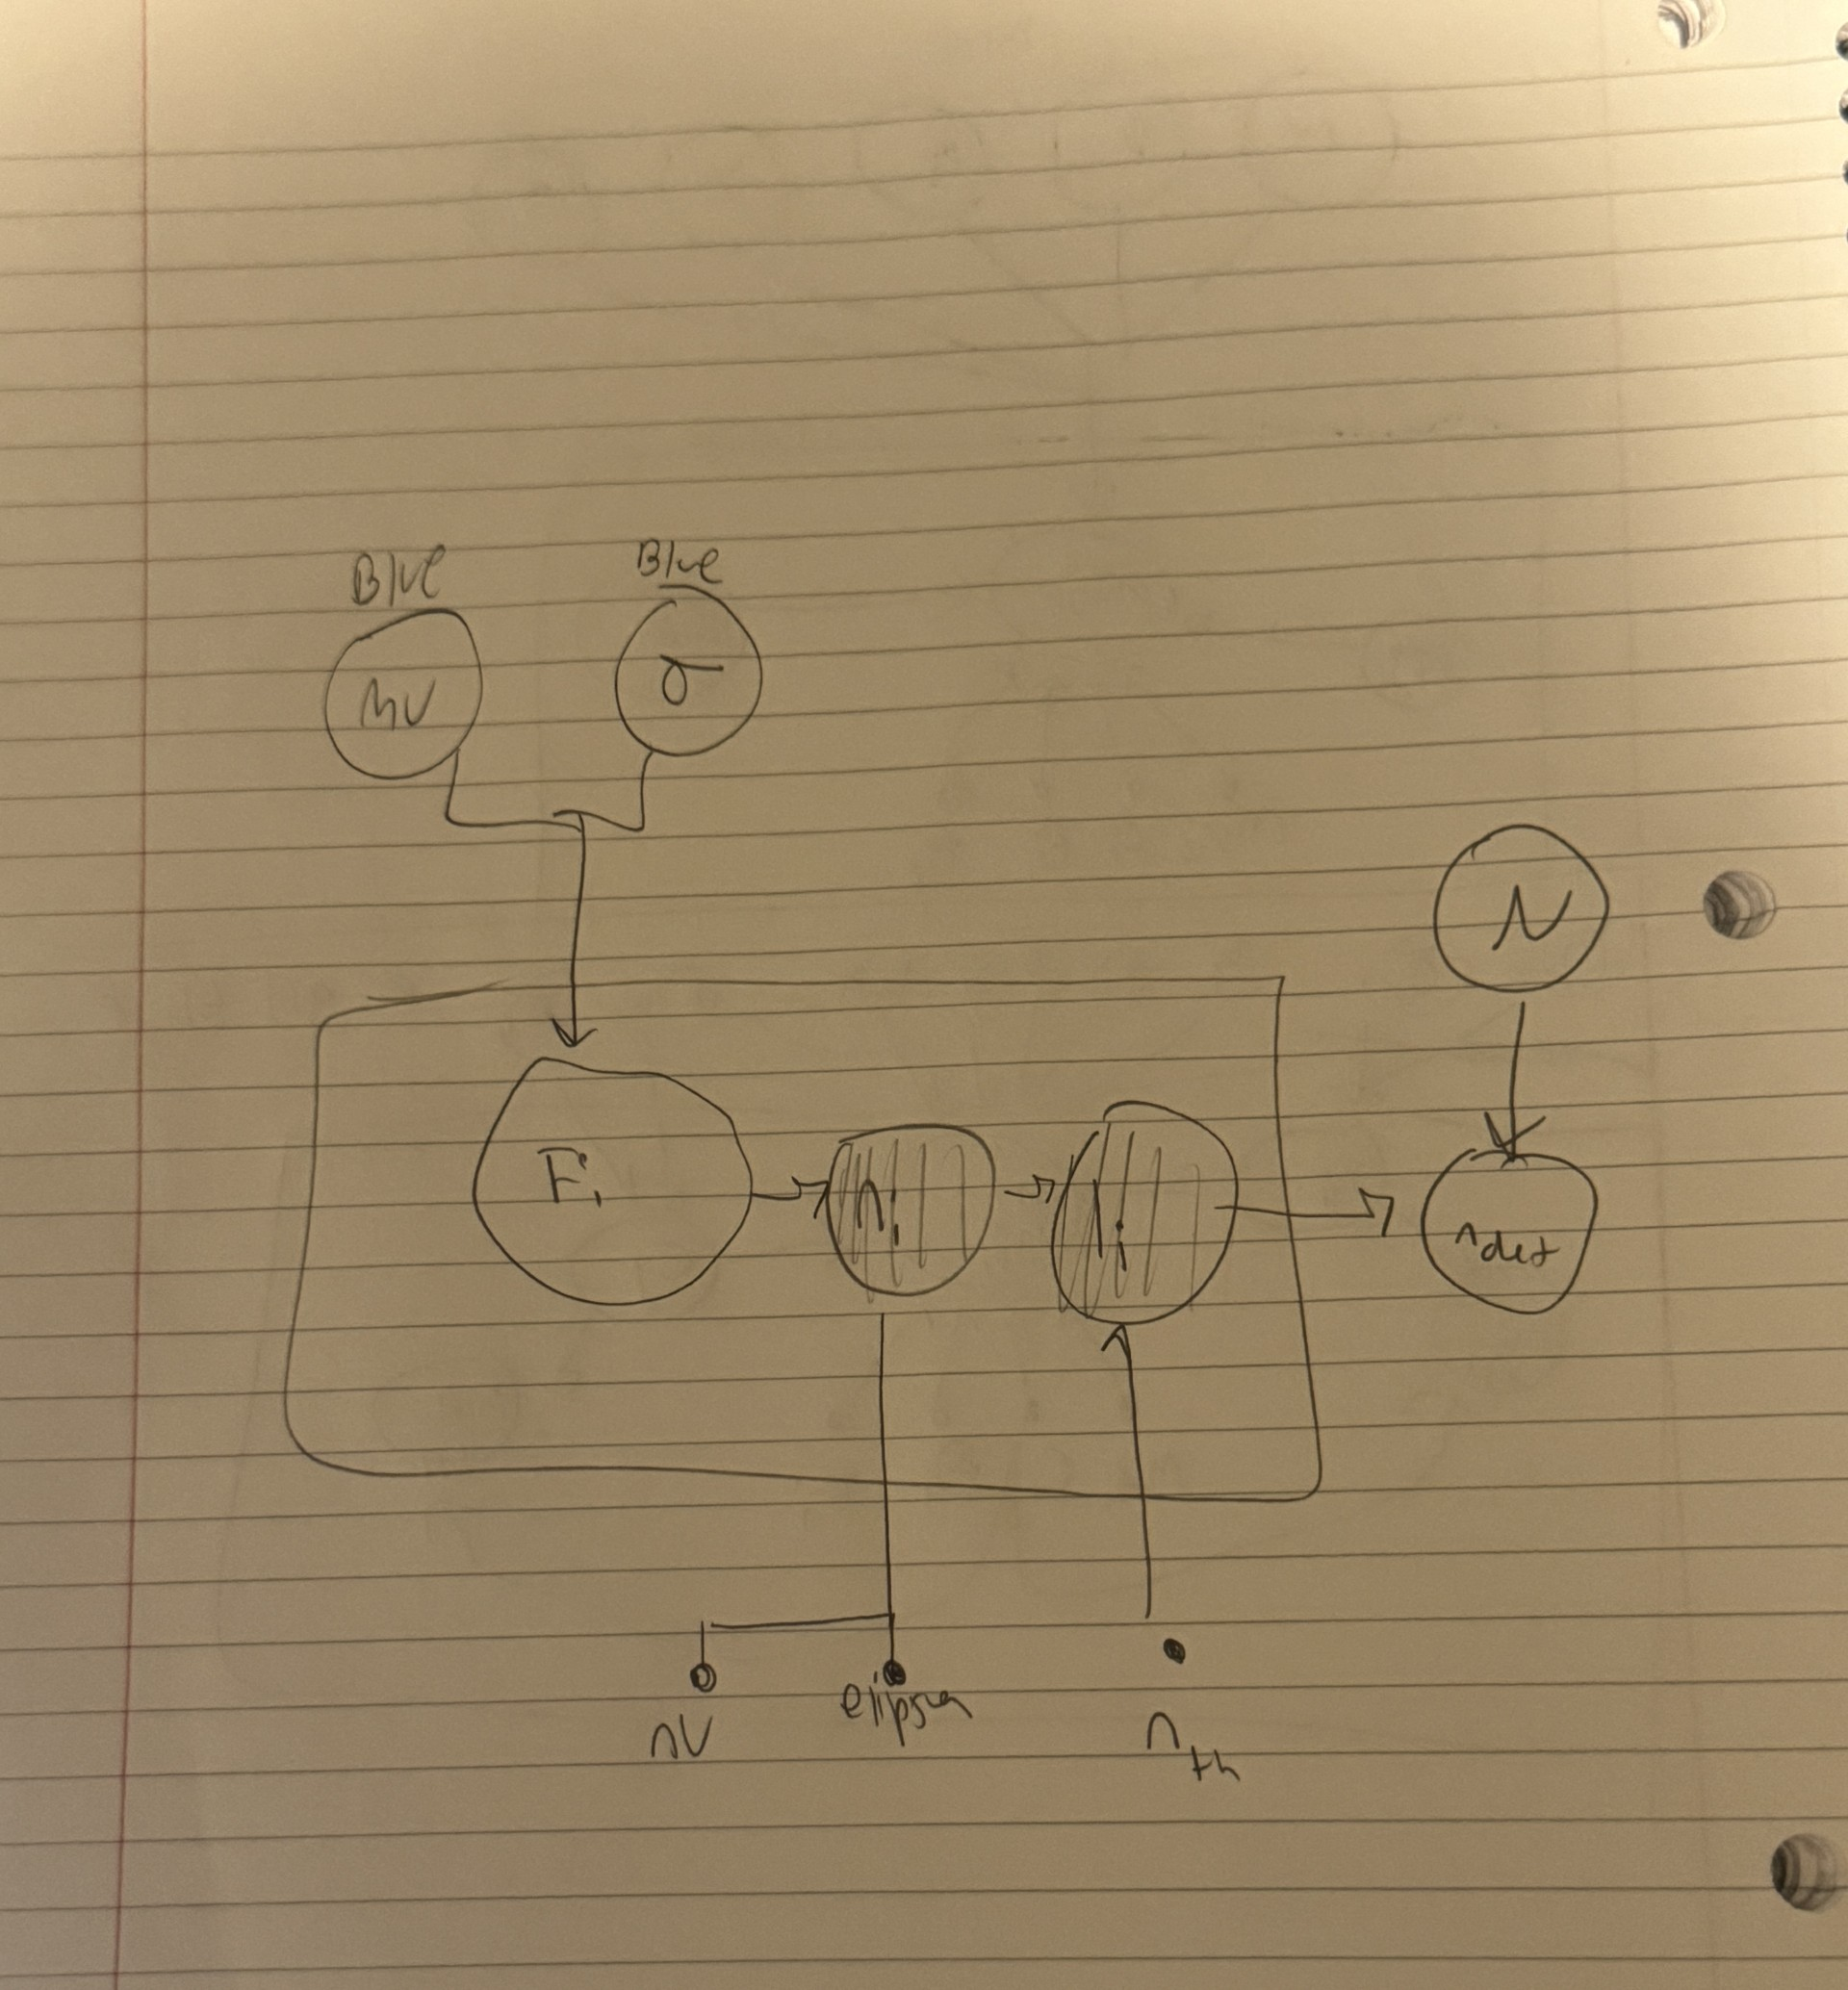

4. 
   - naive: mu = -0.68 +/- 0.03, sigma = 1.15 +/- 0.02
   - with the detector: mu = -1.96 +/- 0.20, sigma = 1.86 +/- 0.10

   f_det = 0.57, so N_total = 2630 +/- 210 and about 1130 +/- 210 sources were missed.

5. simulated survey keeps 1466 sources against 1500 (KS p = 0.81) while p_det does not match the faint end because of Eddington bias. This means the survey cuts on the noisy count, so Poisson noise lets some sources with true flux below the threshold into the catalog. Ignoring the detector gives mu too high (+1.28) and sigma too low (-0.71), because the faint tail is missing and what's left is a truncated Gaussian.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

supernova = SN2006ax | held-out band = r
z = 0.0167, T_Bmax = 53827.11 MJD
bands (blue -> red): {'u': 0.3639, 'B': 0.4351, 'g': 0.4765, 'V': 0.5375, 'r': 0.6223, 'i': 0.7609}
points per band: {'B': 18, 'V': 18, 'i': 17, 'g': 16, 'r': 16, 'u': 15} | peak B flux = 3330.0 uJy


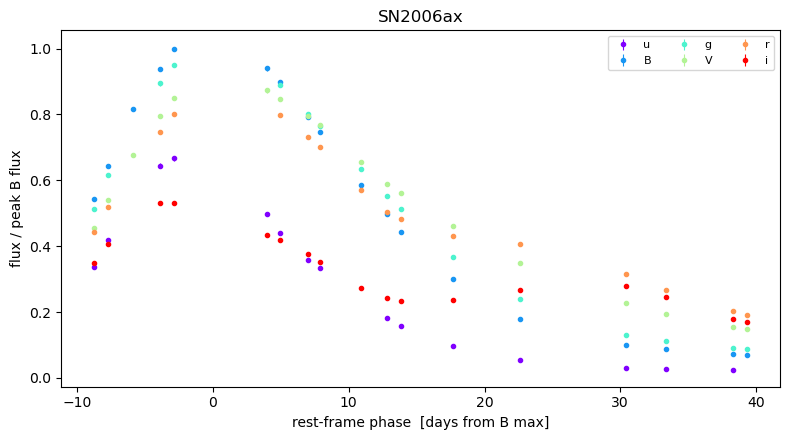


=== held out: r (16 points; trained on 84 points in ['B', 'V', 'g', 'i', 'u']) ===
starts (phase ls, wavelength ls, log marginal likelihood): [(5, 0.05, np.float64(199.5)), (10, 0.1, np.float64(199.5)), (20, 0.3, np.float64(199.5)), (40, 1.0, np.float64(199.5)), (8, 0.02, np.float64(199.5))]
best fit: amplitude^2 = 0.154, phase length scale = 11.48 d, wavelength length scale = 0.112 um, white-noise sd = 0.0038 (fraction of peak)
rms residual = 0.0971 of peak | within 1 sigma = 0.62 (0.62 without the white term) | mean total sigma = 0.1009
nearest training band: 0.085 um away = 0.76 wavelength length scales; training bands bluer / redder than r: (4, 1)


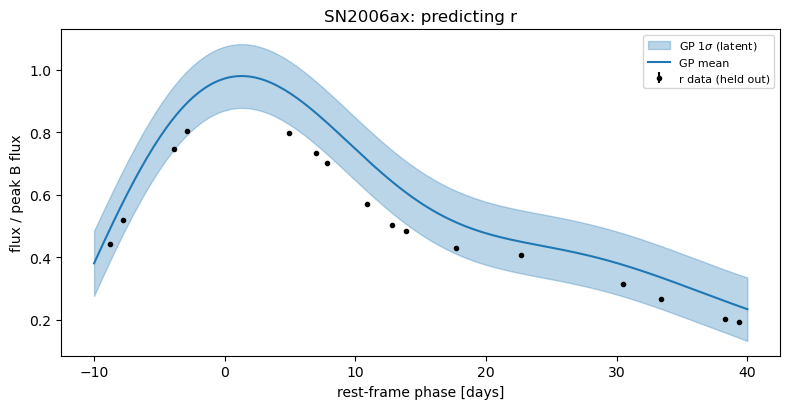


=== held out: u (15 points; trained on 85 points in ['B', 'V', 'g', 'i', 'r']) ===
starts (phase ls, wavelength ls, log marginal likelihood): [(5, 0.05, np.float64(224.2)), (10, 0.1, np.float64(224.2)), (20, 0.3, np.float64(224.2)), (40, 1.0, np.float64(224.2)), (8, 0.02, np.float64(224.2))]
best fit: amplitude^2 = 0.082, phase length scale = 8.41 d, wavelength length scale = 0.154 um, white-noise sd = 0.0001 (fraction of peak)
rms residual = 0.2370 of peak | within 1 sigma = 0.00 (0.00 without the white term) | mean total sigma = 0.0287
nearest training band: 0.071 um away = 0.46 wavelength length scales; training bands bluer / redder than u: (0, 5)


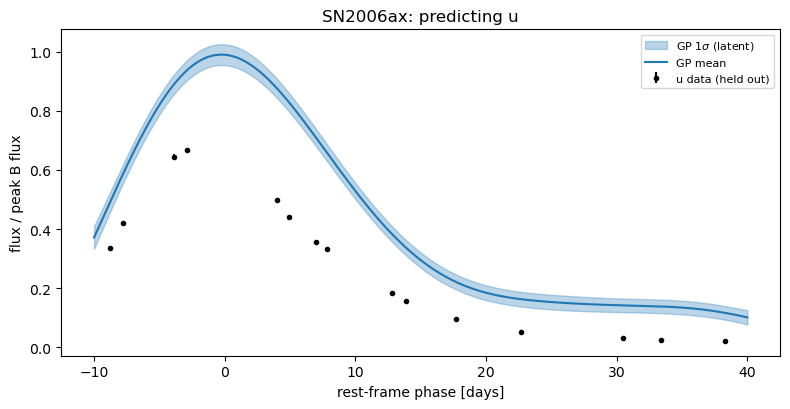


summary
held out    rms (frac of peak)   within 1 sigma  ls_phase [d]  ls_wave [um]
r                       0.0971             0.62         11.48         0.112
u                       0.2370             0.00          8.41         0.154

Data: Carnegie Supernova Project, Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0)


In [5]:
import re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
warnings.filterwarnings("ignore")

# ---- values from your file header (set to None to force auto-parsing) ----
SN_OVERRIDE, HELD_OVERRIDE = None, None
Z_OVERRIDE, TMAX_OVERRIDE = 0.0167, 53827.11

canon = lambda b: 'V' if str(b).strip() in ('V0', 'V1', 'V') else str(b).strip()   # V0, V1, V = one band

# ============================================================
# Look up your supernova and held-out band
# ============================================================
asg = pd.read_csv(LAB + 'csp_assignments.csv')
if SN_OVERRIDE and HELD_OVERRIDE:
    SN, HELD = SN_OVERRIDE, canon(HELD_OVERRIDE)
else:
    row = asg[asg['netid'].astype(str).str.strip() == str(NETID)]
    if row.empty:
        raise ValueError(f"'{NETID}' not found in csp_assignments.csv; set SN_OVERRIDE and HELD_OVERRIDE")
    SN, HELD = str(row['sn'].iloc[0]).strip(), canon(row['holdout_band'].iloc[0])
print(f"supernova = {SN} | held-out band = {HELD}")

# ============================================================
# Load the light curve; header gives z and T_Bmax
# ============================================================
path = LAB + f"csp/{SN}.csv"
with open(path) as fh:
    head = [l.rstrip('\n') for l in fh if l.startswith('#')]
htxt = '\n'.join(head)
def grab(pattern):
    m = re.search(pattern, htxt, re.I)
    return float(m.group(1)) if m else None
z    = Z_OVERRIDE    if Z_OVERRIDE    is not None else grab(r'Redshift[^\n]*?:\s*([0-9]*\.[0-9]+)\s*(?:\n|$)')
tmax = TMAX_OVERRIDE if TMAX_OVERRIDE is not None else grab(r'B-max MJD:\s*([0-9]{5}(?:\.[0-9]+)?)')
if z is None or tmax is None:
    print(htxt)
    raise ValueError(f"could not read z / T_Bmax (got z={z}, tmax={tmax}); set Z_OVERRIDE and TMAX_OVERRIDE")
print(f"z = {z}, T_Bmax = {tmax} MJD")

lc = pd.read_csv(path, comment='#')
lc['band']  = lc['band'].map(canon)
lc['phase'] = (lc['mjd'] - tmax)/(1 + z)
lc['wl']    = lc['band'].map(lc.groupby('band')['wavelength_A'].mean()/1e4)      # microns, one value per band
lc = lc[lc['phase'].between(-10, 40) & np.isfinite(lc['flux_ujy']) & (lc['flux_err_ujy'] > 0)].copy()

B = lc[lc['band'] == 'B']
peakB = B.loc[B['phase'].abs() <= 5, 'flux_ujy'].max()
if not np.isfinite(peakB): peakB = B['flux_ujy'].max()
lc['f'], lc['fe'] = lc['flux_ujy']/peakB, lc['flux_err_ujy']/peakB
bands = list(lc.groupby('band')['wl'].first().sort_values().index)
print("bands (blue -> red):", {b: round(float(lc.loc[lc.band == b, 'wl'].iloc[0]), 4) for b in bands})
print("points per band:", lc['band'].value_counts().to_dict(), "| peak B flux =", round(float(peakB), 2), "uJy")
if HELD not in bands: raise ValueError(f"held-out band {HELD} not in {bands}")

# ============================================================
# 3.1  Every band against phase
# ============================================================
cols = dict(zip(bands, plt.cm.rainbow(np.linspace(0, 1, len(bands)))))
plt.figure(figsize=(8, 4.5))
for b in bands:
    s = lc[lc.band == b]; plt.errorbar(s.phase, s.f, s.fe, fmt='o', ms=3, color=cols[b], label=b, lw=0.8)
plt.xlabel('rest-frame phase  [days from B max]'); plt.ylabel('flux / peak B flux'); plt.title(SN)
plt.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

# ============================================================
# 3.2  GP in (phase, wavelength): fit on every band except the held-out one
# ============================================================
def fit_gp(X, y, e):
    best, rows = None, []
    for lt, lw in [(5, 0.05), (10, 0.1), (20, 0.3), (40, 1.0), (8, 0.02)]:      # several starts
        k = (ConstantKernel(0.3, (1e-3, 1e2)) * RBF([lt, lw], [(1.0, 300.0), (0.02, 10.0)])
             + WhiteKernel(1e-4, (1e-8, 1e-1)))
        gp = GaussianProcessRegressor(k, alpha=e**2, normalize_y=False,
                                      n_restarts_optimizer=2, random_state=0).fit(X, y)
        rows.append((lt, lw, gp.log_marginal_likelihood_value_))
        if best is None or gp.log_marginal_likelihood_value_ > best.log_marginal_likelihood_value_: best = gp
    return best, rows

def predict(gp, X, y, e, Xs):
    k1, noise = gp.kernel_.k1, gp.kernel_.k2.noise_level          # k1 = amplitude*RBF, k2 = white noise
    L = np.linalg.cholesky(k1(X) + np.diag(e**2 + noise))
    Ks = k1(Xs, X)
    mean = Ks @ np.linalg.solve(L.T, np.linalg.solve(L, y))
    v = np.linalg.solve(L, Ks.T)
    return mean, np.maximum(k1.diag(Xs) - np.sum(v**2, axis=0), 0)   # latent mean, latent variance

def run(held, show=True):
    tr, te = lc[lc.band != held], lc[lc.band == held]
    X, y, e = tr[['phase', 'wl']].to_numpy(), tr['f'].to_numpy(), tr['fe'].to_numpy()
    gp, rows = fit_gp(X, y, e)
    k = gp.kernel_
    amp, (lt, lw), noise = k.k1.k1.constant_value, k.k1.k2.length_scale, k.k2.noise_level
    print(f"\n=== held out: {held} ({len(te)} points; trained on {len(tr)} points in {sorted(set(tr.band))}) ===")
    print("starts (phase ls, wavelength ls, log marginal likelihood):", [(a, b, round(c, 1)) for a, b, c in rows])
    print(f"best fit: amplitude^2 = {amp:.3f}, phase length scale = {lt:.2f} d, wavelength length scale = {lw:.3f} um, "
          f"white-noise sd = {np.sqrt(noise):.4f} (fraction of peak)")
    Xt = te[['phase', 'wl']].to_numpy()
    m, v = predict(gp, X, y, e, Xt)
    res = te['f'].to_numpy() - m
    tot = np.sqrt(v + noise + te['fe'].to_numpy()**2)                  # GP + white noise + measurement
    tot_nowhite = np.sqrt(v + te['fe'].to_numpy()**2)                  # GP + measurement only
    out = dict(rms=np.sqrt(np.mean(res**2)), frac=np.mean(np.abs(res) < tot), frac_nw=np.mean(np.abs(res) < tot_nowhite),
               mean_sig=tot.mean(), ls_t=lt, ls_w=lw, n=len(te))
    wl_h, wl_tr = te['wl'].iloc[0], np.array(sorted(set(tr['wl'])))
    out['gap'] = np.min(np.abs(wl_tr - wl_h)); out['sides'] = (int((wl_tr < wl_h).sum()), int((wl_tr > wl_h).sum()))
    print(f"rms residual = {out['rms']:.4f} of peak | within 1 sigma = {out['frac']:.2f} "
          f"({out['frac_nw']:.2f} without the white term) | mean total sigma = {out['mean_sig']:.4f}")
    print(f"nearest training band: {out['gap']:.3f} um away = {out['gap']/lw:.2f} wavelength length scales; "
          f"training bands bluer / redder than {held}: {out['sides']}")
    if show:
        g = np.linspace(-10, 40, 200); Xg = np.column_stack([g, np.full_like(g, wl_h)])
        mg, vg = predict(gp, X, y, e, Xg); sg = np.sqrt(vg)
        plt.figure(figsize=(8, 4.2))
        plt.fill_between(g, mg - sg, mg + sg, color='C0', alpha=0.3, label='GP 1$\\sigma$ (latent)')
        plt.plot(g, mg, 'C0', label='GP mean')
        plt.errorbar(te.phase, te.f, te.fe, fmt='ko', ms=3, label=f'{held} data (held out)')
        plt.xlabel('rest-frame phase [days]'); plt.ylabel('flux / peak B flux'); plt.title(f'{SN}: predicting {held}')
        plt.legend(fontsize=8); plt.tight_layout(); plt.show()
    return out

# ============================================================
# 3.3 held-out band  |  3.4 hold out u instead
# ============================================================
r_held = run(HELD)
r_u = run('u') if 'u' in bands else None

print("\nsummary")
print(f"{'held out':9s} {'rms (frac of peak)':>20s} {'within 1 sigma':>16s} {'ls_phase [d]':>13s} {'ls_wave [um]':>13s}")
for name, r in [(HELD, r_held), ('u', r_u)]:
    if r: print(f"{name:9s} {r['rms']:20.4f} {r['frac']:16.2f} {r['ls_t']:13.2f} {r['ls_w']:13.3f}")
print("\nData: Carnegie Supernova Project, Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0)")

converged to the same log marginal likelihood, 199.5, so this is one optimum): phase length scale 11.5 d, wavelength length scale 0.112 um (about 1100 A), amplitude^2 = 0.154, white-noise sd = 0.004 of the peak.

2. 
Phase length scale is how fast the light curve changes. photons have to diffuse out of the expanding ejecta, and a supernova brightens over about 17 days, and with 11 days as the width of the peak, the flux at two epochs are strongly correlated.
Wavelength length scale: how fast the spectrum changes with wavelength. It is about the spacing between adjacent optical bands (B-g 0.04 um, V-r 0.085 um), because a Type Ia spectrum is a smooth continuum with broad blended lines, so neighboring bands see much the same light curve.


3.
Held out r: rms residual = 0.097 of the peak flux; 62% of the points (10 of 16) are within 1 sigma. The mean total sigma is 0.101, almost the same as the rms residual, so the error bar is about the right size, and 62% against 68% is within the scatter expected for 16 points.

One caution: the GP mean sits above the data over most of the light curve, so the residuals are correlated rather than independent. r is interpolated from bands 0.085 um away, which is 0.76 of a wavelength length scale, so a wide band is reasonable.

Held out u: rms residual = 0.237 of the peak flux (2.4 times worse) and 0 of 15 points within 1 sigma. The mean total sigma is only 0.029, so the error bar is about 8 times too small: the prediction is confidently wrong. The GP peaks near 1.0 where the u data peak near 0.67.

4. u is harder as with r held out there are four training bands bluer and one redder, so it is an interpolation, but u has no bluer band at all (0 bluer, 5 redder), so the GP has to extrapolate. ALso, the kernel is stationary by assuming correlation between bands depend on their wavelength separation. In the near-UV Type Ia flux drops sharply and the u light curve has a different shape so this asumption breaks and is why it says it is 90% correlated. This also gives B's light curve with a tiny error bar. The fit made the wavelength scale longer when u was withheld (0.154 um vs 0.112 um), because the optical bands vary smoothly, so the kernel learned from them is too smooth for the UV.



## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used claude for most of the coding, but did switch to copilot at some point as claude was giving me error messages that should've been easy to fix. I fixed some myself, such as variable names being wrong, not correctly reading the header even when given it, and it did terrible with the plotting I needed from part 1. I let it geenrate the other plot, and reviewed it carefully. It also needed to be instructed to have a lot of error messages/acceptances, as it kept running into variables being weird along the way. It could not figure out what was going on in order to read the data and methods from the midterms, and everytime I tried to add that in, It did not like it. I used claude to help me summarize my findings in part 1, question 2, as I didn't want to retype those numbers, but the analysis is mine. I gave it to claude to format the numbers. 

For part 2, claude also made me a nicer looking graph of the same ideas. I kpet it because it was similar enough and more readable. I added my text responses into Claude for part 1: question 3, and part 2 and 3 and asked it to polish them and add the data numbers. I didn't want to add the data in to every point myself, and wanted to reword some of my answers, some words are still my own however. All ideas at the end are mine, even if reworded slightly. If I didn't understand something that I knew the rght answer to, I made claude explainitin further detail. Part 1 Q 3 was almost entirely generated by claude as I wanted to have it explain the trends I already knew but didn't understand fully

**REFLECTION:**

Had I not been looking over it, it would've had the basis for the problems completely wrong, using a wrong model for part 1. I had to repeadily tell it that both the code was not working and it was getting c and a confused. This may have been because I switched from copilot to claude at some point, and it didn't like what I already had down. It also at some point made numbers and methods up for the midterm solutions instead of what I actually did, even though I told it that is what I did andeven had it entered at some point into this document. 

**VERIFICATION PLAN:**

I plan to make fake data after generating based off of a known sigma, mu, and using the same detecor. In theory, this will test how far off the naive vs corrected end up being from the true value. Basically,making fake data and running it all again. Below is what claude came up with, and it passes the checks:

The corrected fit recovers the input: mu and sigma are each within 1.4 standard errors of the truth, the mean pulls are small (+0.26, -0.31), and the coverage is close to 68%. The naive fit is wrong by 0.75 in mu and 0.47 in sigma, about 30 and 26 standard errors, and its error bars never contain the truth. A failure would have been the corrected fit missing the truth or covering well below 68%.

- How many catalogs: one is not enough, because the scatter of the corrected mu between catalogs is about 0.09 (0.014 x sqrt(40)), so one catalog could hide a bias of that size. With K = 40 the standard error is 0.014, which rules out a bias in mu larger than about 0.03. Seeing a bias of 0.01 would need about 400 catalogs. The coverage is only good to about +/-7% at K = 40 (sqrt(0.68 x 0.32 / 40) = 0.074), so 0.70 and 0.72 are consistent with 68%, and about 100 catalogs would tighten that to +/-5%.

naive     mu   : mean = -0.754 +/- 0.003 (true -1.5) | mean pull = +30.38 | coverage of +/-1 sigma = 0.00
naive     sigma: mean = 1.035 +/- 0.003 (true 1.5) | mean pull = -26.10 | coverage of +/-1 sigma = 0.00
corrected mu   : mean = -1.485 +/- 0.014 (true -1.5) | mean pull = +0.26 | coverage of +/-1 sigma = 0.70
corrected sigma: mean = 1.487 +/- 0.009 (true 1.5) | mean pull = -0.31 | coverage of +/-1 sigma = 0.72


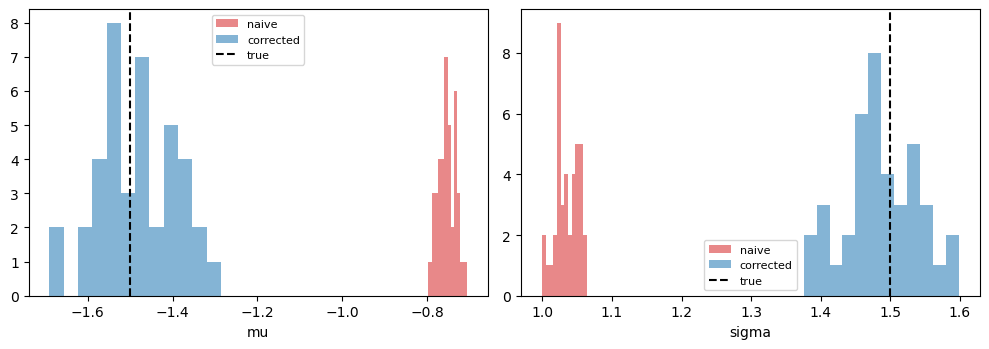

In [6]:
# ============================================================
# Verification: fake catalogs with a known mu, sigma, through the same detector
# ============================================================
MU_T, SIG_T, N_TOT = -1.5, 1.5, 2600      # truth I choose
K   = 40                                   # number of fake catalogs (use 100 for a firmer answer)
CAP = 1300.0                               # saturation, as in the real catalog
rng = np.random.default_rng(1)

out = {'naive': [], 'corrected': []}
for k in range(K):
    F = np.exp(rng.normal(MU_T, SIG_T, N_TOT))      # true fluxes
    n = np.minimum(rng.poisson(lam(F)), CAP)        # Poisson counts, saturated at the cap
    n = n[n > THR0]                                 # the detector
    for name, corr in [('naive', False), ('corrected', True)]:
        p, e = fit(n, THR0, CAP, corr, dl=0.01)[:2]
        out[name].append([p[0], p[1], e[0], e[1]])  # mu, sigma, err_mu, err_sigma

truth = np.array([MU_T, SIG_T])
for name, v in out.items():
    v = np.array(v); est, err = v[:, :2], v[:, 2:]
    pull = (est - truth) / err
    for j, par in enumerate(['mu', 'sigma']):
        print(f"{name:9s} {par:5s}: mean = {est[:, j].mean():.3f} +/- {est[:, j].std(ddof=1)/np.sqrt(K):.3f} "
              f"(true {truth[j]}) | mean pull = {pull[:, j].mean():+.2f} | "
              f"coverage of +/-1 sigma = {np.mean(np.abs(pull[:, j]) < 1):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for j, par in enumerate(['mu', 'sigma']):
    for name, col in [('naive', 'C3'), ('corrected', 'C0')]:
        ax[j].hist(np.array(out[name])[:, j], bins=12, color=col, alpha=0.55, label=name)
    ax[j].axvline(truth[j], color='k', ls='--', label='true')
    ax[j].set_xlabel(par); ax[j].legend(fontsize=8)
plt.tight_layout(); plt.show()